In [1]:
from torchvision import datasets
from torchvision.transforms import ToTensor
import torch
from torch import nn
import torch.nn.functional as F


train_data = datasets.CIFAR10(
    root = "data",
    train = True,
    download = True,
    transform = ToTensor()
)

test_data = datasets.CIFAR10(
    root = "data",
    train = False,
    download = True,
    transform = ToTensor()
)

Files already downloaded and verified
Files already downloaded and verified


In [2]:
type(train_data[0])
a = [data[1] for data in train_data]
print(max(a))
print(min(a))
# max()

9
0


In [3]:
import torch
import torch.nn.functional as F
from torch import nn
import numpy as np
from torch.nn.modules.linear import Linear
from torchviz import make_dot



class Generator(nn.Module):
    def __init__(self, nz, n_class, features_base=256):
        super(Generator, self).__init__()
        self.is_bias = False

        self.label_embedding_generator = nn.Sequential(
            nn.Embedding(n_class, 10 * n_class), 
            nn.Linear(10 * n_class, 5 * n_class)
        )

        self.latent_generator = nn.Sequential(
            nn.Linear(nz, 10 * nz),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.main = nn.Sequential(
            # input is Z, going into a Linear (Regression)
            nn.Linear(10 * nz + 5 * n_class, features_base * 2, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 2),
            nn.ReLU(True),
            # state size. features_base
            nn.Linear(features_base * 2, features_base * 4, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 4),
            nn.ReLU(True),
            # state size. features_base * 4
            nn.Linear(features_base * 4, features_base * 8, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 8),
            nn.ReLU(True),
            # state size. features_base * 8
            nn.Linear(features_base * 8, features_base * 4, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 4),
            nn.ReLU(True),
            # state size. features_base * 4
            nn.Linear(features_base * 4, features_base * 2, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 2),
            nn.ReLU(True),
            # state size. features_base * 2
            nn.Linear(features_base * 2, features_base, bias=self.is_bias),
            nn.BatchNorm1d(features_base),
            nn.ReLU(True),
            # state size. features_base
            nn.Linear(features_base, n_class, bias=self.is_bias),
            # nn.Tanh()
        )

    def forward(self, noises, labels):
        label_output = self.label_embedding_generator(labels)
        noise_output = self.latent_generator(noises)
        # labels = labels.view(-1, 1)
        concat_vector = torch.cat((noise_output, label_output), dim=1)
        # concat_vector.requires_grad_()
        return self.main(concat_vector)

    def conv_output_dimension(self, input_height, kernel, padding, stride=1, dilation=1):
        height_in = input_height
        height_out = np.floor(1 + (height_in + 2 * padding - dilation * (kernel - 1) - 1)/stride)
        return int(height_out)

    def avgpool_output_dimension(self, input_height, kernel, padding, stride):
        height_in = input_height
        height_out = np.floor(1 + (height_in + 2 * padding - kernel)/stride)
        return int(height_out)


class Discriminator(nn.Module):
    def __init__(self, nz, n_class, features_base=256):
        super(Discriminator, self).__init__()
        self.is_bias = False

        self.label_embedding_disc = nn.Sequential(
            nn.Embedding(n_class, 10 * n_class), 
            nn.Linear(10 * n_class, 5 * n_class)
        )

        self.latent_disc = nn.Sequential(
            nn.Linear(nz, 10 * nz),
            nn.LeakyReLU(0.2, inplace=True)
        )


        self.main = nn.Sequential(
            # input is Z, going into a Linear (Regression)
            nn.Linear(10 * nz + 5 * n_class, features_base * 2, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. features_base
            nn.Linear(features_base * 2, features_base * 4, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. features_base * 4
            nn.Linear(features_base * 4, features_base * 8, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. features_base * 8
            nn.Linear(features_base * 8, features_base * 4, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. features_base * 4
            nn.Linear(features_base * 4, features_base * 2, bias=self.is_bias),
            nn.BatchNorm1d(features_base * 2),
            nn.ReLU(True),
            # state size. features_base * 2
            nn.Linear(features_base * 2, features_base, bias=self.is_bias),
            nn.BatchNorm1d(features_base),
            nn.ReLU(True),
            # state size. features_base
            nn.Linear(features_base, 1, bias=self.is_bias),
            nn.Sigmoid()
        )

    def forward(self, noises, labels):
        label_output = self.label_embedding_disc(labels)
        noise_output = self.latent_disc(noises)
        # labels = labels.view(-1, 1)
        concat_vector = torch.cat((noise_output, label_output), dim=1)
        # concat_vector.requires_grad_()
        return self.main(concat_vector)

    def conv_output_dimension(self, input_height, kernel, padding, stride=1, dilation=1):
        height_in = input_height
        height_out = np.floor(1 + (height_in + 2 * padding - dilation * (kernel - 1) - 1)/stride)
        return int(height_out)

    def avgpool_output_dimension(self, input_height, kernel, padding, stride):
        height_in = input_height
        height_out = np.floor(1 + (height_in + 2 * padding - kernel)/stride)
        return int(height_out)

        

In [4]:
from torchviz import make_dot, make_dot_from_trace
# show the computation graph for pytorch
fake = torch.randn((20, 10))
tmplabel = torch.LongTensor([4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 8, 1])
generator = Generator(10, 10)
disc = Discriminator(10, 10)
out_gen = generator(fake, tmplabel)
out_disc = disc(out_gen, tmplabel).view(-1)
G_loss = nn.BCELoss()
label = torch.full((20,), 1, dtype=torch.float)
errG = G_loss(out_disc, label)
dot = make_dot(out_disc, params=dict(generator.named_parameters()), show_attrs=True, show_saved=True)
dot.format = 'png'
dot.render('viz-sample')
errG.backward()

In [5]:

input = torch.randn(3, 5, requires_grad=True)
target = torch.randint(5, (3,), dtype=torch.int64)
print(input)
print(target)
loss = F.cross_entropy(input, target)
print(type(loss))
print(loss)
print(loss.item())
loss.backward()
a = input.max(dim=1).indices
print(a)

target.eq(input.max(dim=1).indices).sum()

tensor([[ 1.2266, -0.0268,  1.4505, -0.8787, -0.6492],
        [-0.9619, -0.8315,  1.3442,  1.0437, -1.4418],
        [ 0.3864,  0.4354, -0.6659,  0.2404,  0.6183]], requires_grad=True)
tensor([4, 4, 0])
<class 'torch.Tensor'>
tensor(2.6352, grad_fn=<NllLossBackward>)
2.6352453231811523
tensor([2, 2, 4])


tensor(0)

In [6]:
input = torch.randn(3, requires_grad=True)
target = torch.empty(3).random_(2)
print(input)
print(target)
loss = F.binary_cross_entropy_with_logits(input, target)
loss.backward()

tensor([ 0.3361, -0.8920, -0.4197], requires_grad=True)
tensor([1., 0., 1.])


In [7]:
input = torch.randn((3, 2), requires_grad=True)
target = torch.rand((3, 2), requires_grad=False)
print(target.detach())
# print(input)
# print(target)
# loss = F.binary_cross_entropy(F.sigmoid(input), target)
# loss.backward()

tensor([[0.8135, 0.6435],
        [0.6852, 0.8164],
        [0.9962, 0.3923]])


In [8]:
a = [1, 2, 3, 4, 5]
print(a)
b = a
c = b[-3:]
print(a)

[1, 2, 3, 4, 5]
[1, 2, 3, 4, 5]


In [9]:
import numpy as np
a = list(range(10))
print(a)
np.random.shuffle(a)
print(a)


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[5, 4, 7, 3, 8, 2, 1, 9, 6, 0]


In [10]:
a = 1

In [11]:
b = nn.Embedding(10, 100)
index0 = torch.LongTensor([0])

In [12]:
a = torch.rand(5)
b = torch.rand(5)
aa = torch.normal(mean=torch.stack([a, b], 0), std=torch.stack([a, b], 0))
print(aa)
c = [a, b]
print(c)
d = torch.stack(c, dim=0)
print(d.shape)
print(d)


tensor([[ 0.3911, -0.0347, -0.3113,  0.0717,  1.2017],
        [ 0.2214,  1.1891, -0.0230,  0.0215,  0.0496]])
[tensor([0.2456, 0.0685, 0.3012, 0.1570, 0.6511]), tensor([0.8017, 0.5839, 0.2161, 0.2147, 0.0377])]
torch.Size([2, 5])
tensor([[0.2456, 0.0685, 0.3012, 0.1570, 0.6511],
        [0.8017, 0.5839, 0.2161, 0.2147, 0.0377]])


In [1]:
from sklearn.cluster import DBSCAN
import numpy as np
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1"

txt_save_path = "txt_result/{}/".format("cifar10")
logits_dict = np.load(txt_save_path + 'real_logits.npy', allow_pickle=True).item()


7


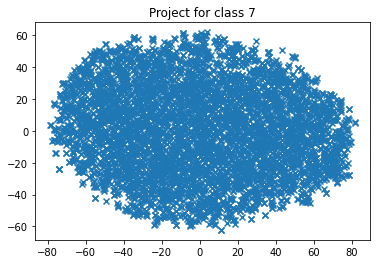

9


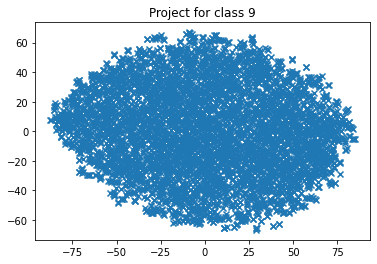

8


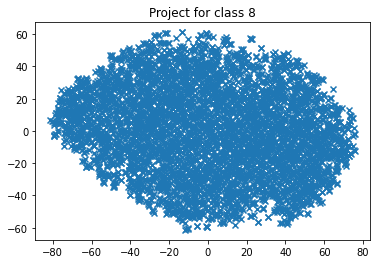

6


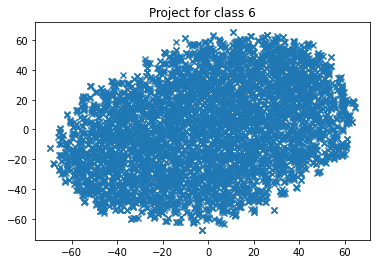

0


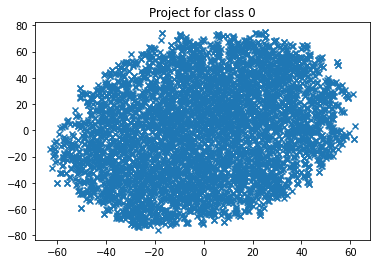

2


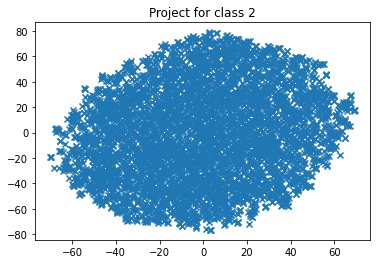

3


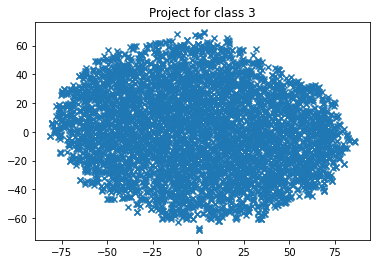

4


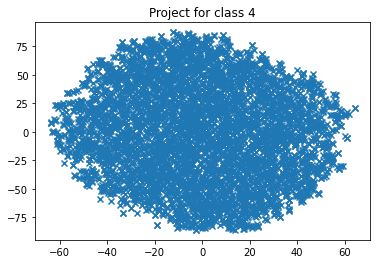

1


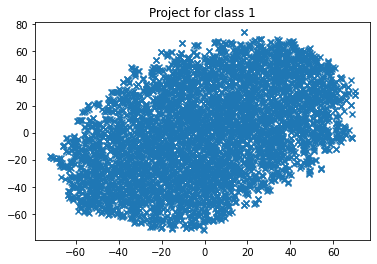

5


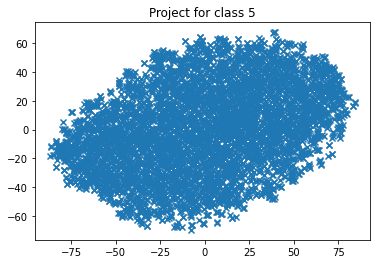

(49990, 10)
(49990, 2)


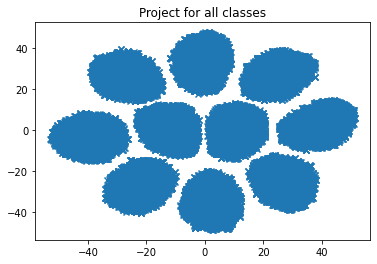

In [3]:
label_list = []
logit_list = []
from collections import Counter
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
# X = np.random.rand(40, 2)
# plt.scatter(X[:, 0], X[:, 1])
# plt.ylim(-1, 2)
# plt.xlim(-1, 2)
# print(X)
# clustering = DBSCAN(eps=0.1).fit(X)
# print(clustering.labels_)
for label, logit in logits_dict.items():
    a = np.array(list(map(np.array, logit)))
    # print(a.shape)
    logit_list.extend(np.array(list(map(np.array, logit))))
    print(label)
    embedding = TSNE(n_components=2)
    logits_transformed = embedding.fit_transform(a)
    # print(logits_transformed.shape)
    plt.scatter(logits_transformed[:, 0], logits_transformed[:, 1], marker="x")
    plt.title("Project for class {}".format(label))
    plt.show()
    # clustering = DBSCAN(eps=8, metric='l1').fit(a)

    # print(dict(Counter(clustering.labels_)))
    # a_label = clustering.fit_predict(a)
    # print(a_label)

b = np.array(logit_list)
print(b.shape)
embedding = TSNE(n_components=2)
logits_transformed = embedding.fit_transform(b)
print(logits_transformed.shape)
plt.scatter(logits_transformed[:, 0], logits_transformed[:, 1], marker="x")
plt.title("Project for all classes")
plt.show()


In [1]:
import numpy as np
import torch
x = torch.tensor([[0, 2], [1, 1], [2, 0]]).T
print(x)
print(x.shape)
# torch.cov(x)
torch.tensor(np.cov(x, rowvar=False))

tensor([[0, 1, 2],
        [2, 1, 0]])
torch.Size([2, 3])


tensor([[ 2.,  0., -2.],
        [ 0.,  0.,  0.],
        [-2.,  0.,  2.]], dtype=torch.float64)

In [2]:
a = [[1, 2], [3, 4], [5, 6]]
# list(zip(*a))
list(zip(*a))

[(1, 3, 5), (2, 4, 6)]

In [69]:

# torch.random.manual_seed()
# a = torch.seed()
torch.manual_seed(3)
random_label = torch.randint(0, 10, (10,))
# b = torch.randn((3))
print(random_label)
torch.seed()
random_label = torch.randint(0, 10, (10,))
print(random_label)

tensor([6, 8, 7, 7, 0, 0, 0, 5, 1, 9])
tensor([2, 1, 3, 6, 2, 9, 2, 0, 5, 3])
